# Phase 6: compare every arm + the evaluation the proposal asks for

**Goal:** put all 8 arms side by side and run the evaluation from the project proposal. No new runs: this notebook only reads saved dialogues. **No API cost, CPU only.**

| model | arms |
|---|---|
| Gemini (05G–08) | baseline, validator, shallow KiL, semi-deep KiL |
| Qwen3-8B (09) | base, sft, deep KiL, validator |

Each model is compared only with its own arms (the agent model differs).

**What this notebook measures** (proposal, "Evaluation and deliverables"):
1. **pass^k for k = 1..8**: the curve shape, and the drop from pass^1 to pass^8 (Hypothesis 1 asks for a *flatter* curve).
2. **Each KiL arm vs the validator**, paired over tasks (Hypothesis 1).
3. **Violations in three types:** (a) illegal tool calls: the 24 data rules, from the 06G checker; (b) dialogue-level: G1 no explicit "yes" before an action, G3 reply and tool call in the same turn, B5 booking without asking about insurance, R3 compensation offered before the user asked (simple text checks); (c) reasoning or argument errors in failed dialogues.
4. **Failure categories** of failed dialogues, the same four as the τ-bench paper (Sec. 5): wrong decision, partially resolve, wrong argument, wrong info.
5. **Violations by turn position** (early / middle / late third of the agent's turns).
6. **Violations on dialogues that still pass**: what final-state scoring hides.
7. **Hand-check of 30 failed dialogues** (5 each from baseline, shallow, semi-deep, Qwen base, sft, deep; the validators are left out): is the error the agent's, the simulator's, the benchmark's, or unclear? I also check the auto failure category. (The τ-bench paper found 4 of 40 failures came from the user simulator.)

**Limits:** the dialogue-level checks are keyword rules (e.g. "yes", "insurance"), so they over- or under-count; the hand-check looks at failure causes, not these counts. G2, G4 and G5 need judgment and are not checked automatically.

**Run first:** 05G–09 (all arms with 8 complete trials).

In [2]:
# mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# install tau-bench (CPU runtime is enough)
%cd /content/drive/MyDrive/cmsc691-10-project2
!pip install -q -e .
print("installed")

/content/drive/MyDrive/cmsc691-10-project2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for tau_bench (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-dataproc 5.32.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-bigquery-storage 2.43.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-resource-manager 1.19.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-bigquery-connection 1.23.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
tensorflow 2.21.0 requires 

In [4]:
%%writefile /content/drive/MyDrive/cmsc691-10-project2/compare.py
# 10: compare every arm and run the evaluation the project proposal asks for.
#   - pass^k for k = 1..8 (curve shape, drop from pass^1 to pass^8)
#   - violations split into three types:
#       (a) illegal tool calls        data rules, found by the 06G checker
#       (b) dialogue-level violations G1 no explicit "yes", G3 reply + tool call in one turn,
#                                     B5 booking without asking about insurance,
#                                     R3 compensation offered before the user asked
#                                     (simple text checks, confirmed by the hand-check)
#       (c) reasoning / argument errors in failed dialogues: missing action, wrong arguments,
#                                     extra action, missing output
#   - failed dialogues split into the tau-bench paper's categories: wrong decision,
#     partially resolve, wrong argument, wrong info
#   - violations by turn position (early / middle / late third of the agent's turns)
#   - violations on dialogues that still PASS (what final-state scoring hides)
#   - 30 failed dialogues exported for a hand-check (agent or simulator?)
import json
import os
import random
import re
from math import comb

import passk
import policy_checker as pc
import violations as V
from tau_bench.envs.airline.data import load_data

N_TASKS, N_TRIALS = 50, 8
CLEAN = [t for t in range(N_TASKS) if t not in V.LABEL_CONFLICT]
GEMINI = [("baseline", "results_gemini_baseline"), ("validator", "results_gemini_validator"),
          ("shallow", "results_gemini_shallow"), ("semi-deep", "results_gemini_semideep")]
QWEN = [("qwen base", "results_deep_qwen_base"), ("qwen sft", "results_deep_qwen_sft"),
        ("qwen deep", "results_deep_qwen_deep"), ("qwen validator", "results_deep_qwen_validator")]
ARMS = GEMINI + QWEN
MODEL_OF = {a: ("gemini" if (a, d) in GEMINI else "qwen") for a, d in ARMS}

G1_TOOLS = {"book_reservation", "update_reservation_flights", "update_reservation_baggages",
            "update_reservation_passengers"}       # G1's 5 actions (upgrade_cabin = update_reservation_flights)
YES = re.compile(r"\b(yes|yeah|yep|sure|ok|okay|confirm\w*|go ahead|proceed|correct|that'?s right|please do|do it)\b", re.I)
ASK_COMP = re.compile(r"compensat|refund|voucher|certificate|reimburs|make up for|credit", re.I)


# ------------------------------------------------------------ loading and pass^k
def full_table(root, d):
    """{trial: {task: row}} with only the complete trials."""
    tab = passk.table(os.path.join(root, d))
    return {t: v for t, v in tab.items() if len(v) == N_TASKS}


def counts(tab):
    return passk.success_counts(tab, range(N_TASKS))


def pass_k(c, k, tasks=None):
    tasks = tasks if tasks is not None else list(range(N_TASKS))
    return sum(comb(c[t], k) / comb(N_TRIALS, k) for t in tasks) / len(tasks)


def delta(c_new, c_old, tasks, k, boot=2000, seed=0):
    est = pass_k(c_new, k, tasks) - pass_k(c_old, k, tasks)
    rng = random.Random(seed)
    s = []
    for _ in range(boot):
        pick = [rng.choice(tasks) for _ in tasks]
        s.append(pass_k(c_new, k, pick) - pass_k(c_old, k, pick))
    s.sort()
    lo, hi = s[int(0.025 * boot)], s[int(0.975 * boot) - 1]
    return est, lo, hi


# ------------------------------------------------------------ one dialogue
def _norm(kw):
    return json.dumps(kw, sort_keys=True)


def analyze(row, graph):
    """Everything 10 needs from one dialogue."""
    traj = row.get("traj") or []
    obs = {m["tool_call_id"]: m["content"] for m in traj if m.get("role") == "tool"}
    assistant_idx = [i for i, m in enumerate(traj) if m.get("role") == "assistant"]
    n_turns = max(len(assistant_idx), 1)
    pos_of = {i: j / n_turns for j, i in enumerate(assistant_idx)}     # 0 = first agent turn, ~1 = last

    data, hist = load_data(), []
    data_viol, executed = [], []
    dlg_viol = []
    asked_insurance = False
    user_asked_comp = False
    last_user = ""
    for i, m in enumerate(traj):
        role = m.get("role")
        if role == "user":
            last_user = m.get("content") or ""
            if ASK_COMP.search(last_user):
                user_asked_comp = True
            continue
        if role != "assistant":
            continue
        text = m.get("content") or ""
        if "insurance" in text.lower():
            asked_insurance = True
        calls = m.get("tool_calls") or []
        if not calls:
            continue
        if text.strip():
            dlg_viol.append({"rule": "G3", "pos": pos_of[i]})
        c = calls[0]
        name = c["function"]["name"]
        try:
            kw = json.loads(c["function"]["arguments"] or "{}")
        except json.JSONDecodeError:
            continue
        if c["id"] not in obs or name not in V.TOOLS or not isinstance(kw, dict):
            continue
        blocked = str(obs[c["id"]]).startswith(V.BLOCK_TAG)
        if name in pc.WRITE_TOOLS:
            for v in pc.check(name, kw, data, hist, graph):
                data_viol.append({"sources": v["sources"], "tool": name, "pos": pos_of[i],
                                  "status": "blocked" if blocked else "executed"})
        if blocked:
            continue
        try:
            out = V.TOOLS[name].invoke(data=data, **kw)
        except Exception as e:
            out = f"Error: {e}"
        if name in pc.WRITE_TOOLS and not str(out).startswith("Error"):
            hist.append({"name": name, "kwargs": kw})
            executed.append((name, _norm(kw)))
            if name in G1_TOOLS and not YES.search(last_user):
                dlg_viol.append({"rule": "G1", "pos": pos_of[i]})
            if name == "book_reservation" and not asked_insurance:
                dlg_viol.append({"rule": "B5", "pos": pos_of[i]})
            if name == "send_certificate" and not user_asked_comp:
                dlg_viol.append({"rule": "R3", "pos": pos_of[i]})

    passed = row["reward"] >= 1 - 1e-6
    labels, category = [], None
    if not passed:
        ri = ((row.get("info") or {}).get("reward_info") or {}).get("info") or {}
        gt = [(a["name"], _norm(a["kwargs"])) for a in ((row.get("info") or {}).get("task") or {}).get("actions", [])
              if a["name"] in pc.WRITE_TOOLS]
        ex_names = {n for n, _ in executed}
        gt_names = {n for n, _ in gt}
        violated = any(v["status"] == "executed" for v in data_viol)
        missing = [n for n, _ in gt if n not in ex_names]
        done = [n for n, _ in gt if n in ex_names]
        wrong_args = any(n in ex_names and (n, k) not in executed for n, k in gt)
        extra = any(n not in gt_names for n, _ in executed)
        if violated: labels.append("rule violation")
        if missing: labels.append("missing action")
        if wrong_args: labels.append("wrong arguments")
        if extra: labels.append("extra action")
        if "r_outputs" in ri: labels.append("missing output")
        # one category per failed dialogue, as in the tau-bench paper (Sec. 5, failure breakdown)
        if violated or extra or (gt and not done):
            category = "wrong decision"          # wrong type of call: broke a rule, did something not asked, or did not act
        elif missing and done:
            category = "partially resolve"       # did some of the requests, not all
        elif wrong_args:
            category = "wrong argument"
        elif "r_outputs" in ri:
            category = "wrong info"              # did not give the user the information asked for
        else:
            category = "other"
    return {"passed": passed, "data_viol": data_viol, "dlg_viol": dlg_viol, "labels": labels,
            "category": category, "n_turns": len(assistant_idx)}


CATEGORIES = ["wrong decision", "partially resolve", "wrong argument", "wrong info", "other"]


def position(p):
    return "early" if p < 1 / 3 else ("middle" if p < 2 / 3 else "late")


# ------------------------------------------------------------ hand-check export
def export_dialogue(path, arm, trial, task, row, res):
    traj = row.get("traj") or []
    task_info = (row.get("info") or {}).get("task") or {}
    lines = [f"# {arm} | trial {trial} | task {task} | reward {row['reward']}",
             f"**Auto category:** {res['category']} | labels: {', '.join(res['labels']) or '-'}",
             f"**Data violations:** {[(v['tool'], v['sources'], v['status']) for v in res['data_viol']]}",
             f"**Dialogue violations:** {[v['rule'] for v in res['dlg_viol']]}",
             "", "## User goal (simulator instruction)", task_info.get("instruction", ""),
             "", "## Answer key (write actions)"]
    for a in task_info.get("actions", []):
        if a["name"] in pc.WRITE_TOOLS:
            lines.append(f"- `{a['name']}` {json.dumps(a['kwargs'])}")
    lines += ["", "## Dialogue"]
    for m in traj[1:]:                                    # skip the long system prompt
        role = m.get("role")
        if role == "tool":
            lines.append(f"**tool →** {str(m.get('content'))[:400]}")
        elif role == "assistant" and m.get("tool_calls"):
            c = m["tool_calls"][0]["function"]
            pre = (m.get("content") or "").strip()
            lines.append(f"**agent:** {pre} `CALL {c['name']}({c['arguments']})`")
        else:
            lines.append(f"**{'user' if role == 'user' else 'agent'}:** {m.get('content')}")
        lines.append("")
    open(path, "w").write("\n".join(lines))

Writing /content/drive/MyDrive/cmsc691-10-project2/compare.py


In [5]:
# load every arm; each must have 8 complete trials
import os, sys, importlib, json
import pandas as pd
from IPython.display import display
os.chdir("/content/drive/MyDrive/cmsc691-10-project2"); sys.path.insert(0, "/content/drive/MyDrive/cmsc691-10-project2")
import compare as C, policy_checker as pc
importlib.reload(C)
OUT = "/content/drive/MyDrive/cmsc691-10-project2/results_compare"
os.makedirs(OUT, exist_ok=True)
graph = pc.load_graph()
TAB, CNT = {}, {}
for arm, d in C.ARMS:
    TAB[arm] = C.full_table("/content/drive/MyDrive/cmsc691-10-project2", d)
    CNT[arm] = C.counts(TAB[arm])
    print(f"{arm:15s} {d:32s} complete trials: {len(TAB[arm])}")
assert all(len(t) == C.N_TRIALS for t in TAB.values()), "every arm needs 8 complete trials"

baseline        results_gemini_baseline          complete trials: 8
validator       results_gemini_validator         complete trials: 8
shallow         results_gemini_shallow           complete trials: 8
semi-deep       results_gemini_semideep          complete trials: 8
qwen base       results_deep_qwen_base           complete trials: 8
qwen sft        results_deep_qwen_sft            complete trials: 8
qwen deep       results_deep_qwen_deep           complete trials: 8
qwen validator  results_deep_qwen_validator      complete trials: 8


In [6]:
# 1. pass^k for every arm, k = 1..8, and the drop from pass^1 to pass^8 (smaller = flatter)
rows = []
for arm, _ in C.ARMS:
    ks = [C.pass_k(CNT[arm], k) for k in range(1, 9)]
    rows.append({"model": C.MODEL_OF[arm], "arm": arm, **{f"k={k}": round(v, 3) for k, v in zip(range(1, 9), ks)},
                 "drop 1→8": f"{(1 - ks[7] / ks[0]) * 100:.0f}%" if ks[0] else "-"})
passk_table = pd.DataFrame(rows).set_index(["model", "arm"])
passk_table.to_csv(f"{OUT}/passk_all_arms.csv")
display(passk_table)

k=1    k=2    k=3    k=4    k=5    k=6    k=7   k=8  \
model  arm                                                                     
gemini baseline        0.525  0.443  0.406  0.386  0.376  0.370  0.365  0.36   
       validator       0.573  0.501  0.460  0.432  0.412  0.398  0.388  0.38   
       shallow         0.520  0.432  0.392  0.369  0.355  0.347  0.343  0.34   
       semi-deep       0.520  0.455  0.418  0.395  0.381  0.371  0.365  0.36   
qwen   qwen base       0.147  0.071  0.043  0.029  0.023  0.021  0.020  0.02   
       qwen sft        0.253  0.157  0.111  0.083  0.065  0.053  0.045  0.04   
       qwen deep       0.340  0.272  0.230  0.197  0.171  0.149  0.133  0.12   
       qwen validator  0.390  0.312  0.273  0.248  0.230  0.217  0.207  0.20   

                      drop 1→8  
model  arm                      
gemini baseline            31%  
       validator           34%  
       shallow             35%  
       semi-deep           31%  
qwen   qwen base           86%  
       qwen sft            84%  
       qwen deep           65%  
       qwen validator      49%

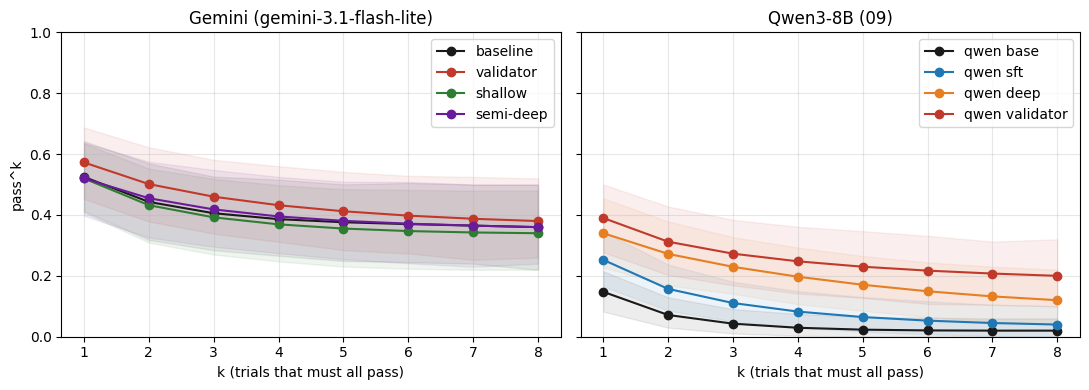

In [7]:
# figure: pass^k curves, one panel per model, 95% bootstrap CI
import matplotlib.pyplot as plt
import passk; importlib.reload(passk)
COL = {"baseline": "#1A1A1A", "validator": "#C0392B", "shallow": "#2E7D32", "semi-deep": "#6A1B9A",
       "qwen base": "#1A1A1A", "qwen validator": "#C0392B", "qwen sft": "#1F77B4", "qwen deep": "#E67E22"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (title, arms) in zip(axes, [("Gemini (gemini-3.1-flash-lite)", C.GEMINI), ("Qwen3-8B (09)", C.QWEN)]):
    for arm, d in arms:
        _, r = passk.curve(d, C.N_TASKS)
        ks = [x["k"] for x in r]
        ax.fill_between(ks, [x["ci_low"] for x in r], [x["ci_high"] for x in r], alpha=0.08, color=COL[arm])
        ax.plot(ks, [x["pass^k"] for x in r], "o-", color=COL[arm], label=arm)
    ax.set_title(title); ax.set_xlabel("k (trials that must all pass)")
    ax.set_xticks(range(1, 9)); ax.set_ylim(0, 1); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("pass^k")
plt.tight_layout()
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/all_arms_passk.png", dpi=200, bbox_inches="tight"); plt.show()

In [8]:
# 2. Hypothesis 1: every KiL arm vs the validator of the same model (paired over tasks)
#    also vs the baseline of the same model. * = 95% CI does not include 0
PAIRS = [("shallow", "validator"), ("semi-deep", "validator"), ("qwen deep", "qwen validator"),
         ("shallow", "baseline"), ("semi-deep", "baseline"), ("qwen deep", "qwen base"), ("qwen deep", "qwen sft")]
rows = []
for new, old in PAIRS:
    for label, tasks in [("all 50", list(range(C.N_TASKS))), ("clean 42", C.CLEAN)]:
        r = {"compare": f"{new} vs {old}", "tasks": label}
        for k in (1, 2, 4, 8):
            est, lo, hi = C.delta(CNT[new], CNT[old], tasks, k)
            r[f"Δpass^{k}"] = f"{est:+.3f} [{lo:+.3f}, {hi:+.3f}]" + (" *" if lo > 0 or hi < 0 else "")
        rows.append(r)
h1 = pd.DataFrame(rows).set_index(["compare", "tasks"])
h1.to_csv(f"{OUT}/paired_tests.csv")
display(h1)

Δpass^1  \
compare                     tasks                                 
shallow vs validator        all 50      -0.052 [-0.115, +0.012]   
                            clean 42  -0.092 [-0.158, -0.039] *   
semi-deep vs validator      all 50    -0.052 [-0.110, -0.002] *   
                            clean 42  -0.065 [-0.134, -0.009] *   
qwen deep vs qwen validator all 50      -0.050 [-0.105, +0.005]   
                            clean 42    -0.060 [-0.125, +0.009]   
shallow vs baseline         all 50      -0.005 [-0.060, +0.052]   
                            clean 42    +0.012 [-0.051, +0.074]   
semi-deep vs baseline       all 50      -0.005 [-0.087, +0.070]   
                            clean 42    +0.039 [-0.045, +0.116]   
qwen deep vs qwen base      all 50    +0.193 [+0.092, +0.297] *   
                            clean 42  +0.232 [+0.122, +0.348] *   
qwen deep vs qwen sft       all 50    +0.088 [+0.027, +0.155] *   
                            clean 42  +0.104 [+0.036, +0.182] *   

                                                        Δpass^2  \
compare                     tasks                                 
shallow vs validator        all 50    -0.069 [-0.132, -0.005] *   
                            clean 42  -0.103 [-0.172, -0.043] *   
semi-deep vs validator      all 50      -0.046 [-0.105, +0.009]   
                            clean 42    -0.055 [-0.127, +0.008]   
qwen deep vs qwen validator all 50      -0.040 [-0.107, +0.021]   
                            clean 42    -0.048 [-0.127, +0.029]   
shallow vs baseline         all 50      -0.011 [-0.079, +0.059]   
                            clean 42    +0.009 [-0.071, +0.085]   
semi-deep vs baseline       all 50      +0.012 [-0.079, +0.097]   
                            clean 42    +0.056 [-0.035, +0.145]   
qwen deep vs qwen base      all 50    +0.201 [+0.112, +0.296] *   
                            clean 42  +0.239 [+0.138, +0.348] *   
qwen deep vs qwen sft       all 50    +0.115 [+0.049, +0.192] *   
                            clean 42  +0.137 [+0.062, +0.224] *   

                                                        Δpass^4  \
compare                     tasks                                 
shallow vs validator        all 50      -0.063 [-0.133, +0.001]   
                            clean 42  -0.087 [-0.169, -0.020] *   
semi-deep vs validator      all 50      -0.037 [-0.104, +0.031]   
                            clean 42    -0.044 [-0.132, +0.034]   
qwen deep vs qwen validator all 50      -0.051 [-0.140, +0.033]   
                            clean 42    -0.060 [-0.165, +0.041]   
shallow vs baseline         all 50      -0.017 [-0.101, +0.068]   
                            clean 42    +0.003 [-0.098, +0.097]   
semi-deep vs baseline       all 50      +0.009 [-0.088, +0.104]   
                            clean 42    +0.046 [-0.062, +0.147]   
qwen deep vs qwen base      all 50    +0.168 [+0.088, +0.258] *   
                            clean 42  +0.200 [+0.110, +0.303] *   
qwen deep vs qwen sft       all 50    +0.115 [+0.045, +0.193] *   
                            clean 42  +0.136 [+0.057, +0.232] *   

                                                        Δpass^8  
compare                     tasks                                
shallow vs validator        all 50      -0.040 [-0.120, +0.040]  
                            clean 42    -0.048 [-0.143, +0.024]  
semi-deep vs validator      all 50      -0.020 [-0.100, +0.060]  
                            clean 42    -0.024 [-0.143, +0.071]  
qwen deep vs qwen validator all 50      -0.080 [-0.200, +0.040]  
                            clean 42    -0.095 [-0.238, +0.048]  
shallow vs baseline         all 50      -0.020 [-0.120, +0.080]  
                            clean 42    +0.000 [-0.119, +0.119]  
semi-deep vs baseline       all 50      +0.000 [-0.100, +0.100]  
                            clean 42    +0.024 [-0.095, +0.143]  
qwen deep vs qwen base      all 50    +0.100 

In [9]:
# analyze every dialogue once (8 arms x 400 dialogues; takes a few minutes)
import time
t0 = time.time()
DLG = []
for arm, _ in C.ARMS:
    for trial, rows in sorted(TAB[arm].items()):
        for task, row in sorted(rows.items()):
            res = C.analyze(row, graph)
            DLG.append({"arm": arm, "model": C.MODEL_OF[arm], "trial": trial, "task": task,
                        "clean": task in C.CLEAN, **res})
df = pd.DataFrame(DLG)
df.drop(columns=["data_viol", "dlg_viol"]).assign(labels=df.labels.map(", ".join)).to_csv(f"{OUT}/dialogues.csv", index=False)
print(f"{len(df)} dialogues in {(time.time() - t0) / 60:.1f} min")

3200 dialogues in 3.8 min


In [10]:
# 3. violations in three types (per 400 dialogues)
def n_data(r, status): return sum(v["status"] == status for v in r)
rows = []
for arm, _ in C.ARMS:
    a = df[df.arm == arm]
    failed = a[~a.passed]
    rows.append({"model": C.MODEL_OF[arm], "arm": arm,
                 "(a) illegal tool calls: executed": int(a.data_viol.map(lambda r: n_data(r, "executed")).sum()),
                 "(a) blocked by validator": int(a.data_viol.map(lambda r: n_data(r, "blocked")).sum()),
                 **{f"(b) {g}": int(a.dlg_viol.map(lambda r: sum(v["rule"] == g for v in r)).sum())
                    for g in ("G1", "G3", "B5", "R3")},
                 "(c) failed dialogues": len(failed),
                 "(c) wrong arguments": int(failed.labels.map(lambda l: "wrong arguments" in l).sum()),
                 "(c) missing action": int(failed.labels.map(lambda l: "missing action" in l).sum()),
                 "(c) missing output": int(failed.labels.map(lambda l: "missing output" in l).sum())})
types = pd.DataFrame(rows).set_index(["model", "arm"])
types.to_csv(f"{OUT}/violation_types.csv")
display(types.T)
print("G1 = no explicit 'yes' before the action; G3 = reply and tool call in one turn;")
print("B5 = booked without asking about insurance; R3 = certificate before the user asked for compensation")

model                              gemini                              \
arm                              baseline validator shallow semi-deep   
(a) illegal tool calls: executed       70         0      31         2   
(a) blocked by validator                0        69       0         0   
(b) G1                                 31        39      22        18   
(b) G3                                  1         9       9       163   
(b) B5                                  5         4       0         1   
(b) R3                                  0         0       0         0   
(c) failed dialogues                  190       171     192       192   
(c) wrong arguments                    50        42      55        34   
(c) missing action                    110       131     122       151   
(c) missing output                     16        17      16        15   

model                                 qwen                                    
arm                              qwen base qwen sft qwen deep qwen validator  
(a) illegal tool calls: executed       349      182        76              0  
(a) blocked by validator                 0        0         0            407  
(b) G1                                 211       60         6            162  
(b) G3                                  11        4        20             10  
(b) B5                                  26        5         1             16  
(b) R3                                   2        1         0              0  
(c) failed dialogues                   341      299       264            244  
(c) wrong arguments                     90       71        26             75  
(c) missing action                      99      147       205            137  
(c) missing output                      20       26        24             25

G1 = no explicit 'yes' before the action; G3 = reply and tool call in one turn;
B5 = booked without asking about insurance; R3 = certificate before the user asked for compensation


category,wrong decision,partially resolve,wrong argument,wrong info,other
arm,,,,,
baseline,65%,16%,17%,0%,2%
validator,66%,11%,22%,0%,1%
shallow,65%,10%,22%,0%,3%
semi-deep,72%,11%,16%,0%,2%
qwen base,88%,2%,7%,2%,1%
qwen sft,85%,3%,9%,2%,1%
qwen deep,90%,3%,3%,1%,3%
qwen validator,59%,11%,24%,4%,2%


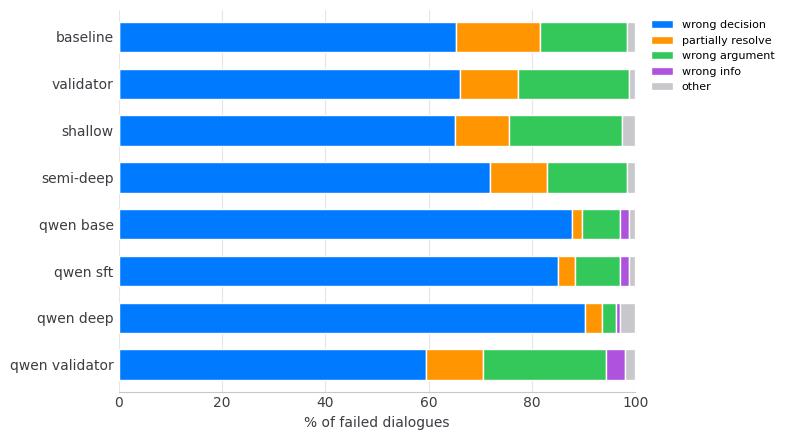

wrong decision = broke a rule, did an action not asked for, or did not act;
partially resolve = did some of the requests; wrong argument = right action, wrong arguments;
wrong info = did not give the user the information asked for


In [19]:
# 4. failure categories of failed dialogues, as in the tau-bench paper (share of failures)
cat = (df[~df.passed].groupby("arm").category.value_counts(normalize=True).unstack(fill_value=0)
       .reindex(index=[a for a, _ in C.ARMS], columns=C.CATEGORIES, fill_value=0))
cat.to_csv(f"{OUT}/failure_categories.csv")
display((cat * 100).round(0).astype(int).astype(str) + "%")
# Apple system colors: blue, orange, green, purple, gray
APPLE = ["#007AFF", "#FF9500", "#34C759", "#AF52DE", "#C7C7CC"]
plt.rcParams.update({"font.family": "sans-serif",
                     "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"]})
ax = (cat * 100).plot(kind="barh", stacked=True, figsize=(8, 4.5), color=APPLE, width=0.65, edgecolor="white")
ax.invert_yaxis()
ax.set_xlabel("% of failed dialogues", color="#3C3C43"); ax.set_ylabel("")
ax.set_xlim(0, 100)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color("#C7C7CC")
ax.tick_params(colors="#3C3C43", length=0)
ax.grid(axis="x", color="#E5E5EA", linewidth=0.8); ax.set_axisbelow(True)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig("figures/failure_categories.png", dpi=200, bbox_inches="tight"); plt.show()
print("wrong decision = broke a rule, did an action not asked for, or did not act;")
print("partially resolve = did some of the requests; wrong argument = right action, wrong arguments;")
print("wrong info = did not give the user the information asked for")

In [12]:
# 5. violations by turn position: early / middle / late third of the agent's turns
rows = []
for arm, _ in C.ARMS:
    a = df[df.arm == arm]
    pos = {"early": 0, "middle": 0, "late": 0}
    for r in a.data_viol:
        for v in r:
            if v["status"] == "executed": pos[C.position(v["pos"])] += 1
    for r in a.dlg_viol:
        for v in r:
            if v["rule"] != "G3": pos[C.position(v["pos"])] += 1      # G3 is about format, not timing
    tot = max(sum(pos.values()), 1)
    rows.append({"model": C.MODEL_OF[arm], "arm": arm, "violations": sum(pos.values()),
                 **{p: f"{n} ({n / tot * 100:.0f}%)" for p, n in pos.items()}})
display(pd.DataFrame(rows).set_index(["model", "arm"]))

violations      early     middle       late
model  arm                                                        
gemini baseline               106     1 (1%)   18 (17%)   87 (82%)
       validator               43     0 (0%)     4 (9%)   39 (91%)
       shallow                 53     0 (0%)   12 (23%)   41 (77%)
       semi-deep               21     0 (0%)     1 (5%)   20 (95%)
qwen   qwen base              588  148 (25%)  187 (32%)  253 (43%)
       qwen sft               248   47 (19%)   80 (32%)  121 (49%)
       qwen deep               83   10 (12%)   28 (34%)   45 (54%)
       qwen validator         178   28 (16%)   61 (34%)   89 (50%)

In [13]:
# 6. violations on dialogues that PASS: final-state scoring calls them correct
rows = []
for arm, _ in C.ARMS:
    a = df[df.arm == arm]; p = a[a.passed]
    has_data = p.data_viol.map(lambda r: n_data(r, "executed") > 0)
    has_dlg = p.dlg_viol.map(lambda r: any(v["rule"] in ("G1", "B5", "R3") for v in r))
    rows.append({"model": C.MODEL_OF[arm], "arm": arm, "passed dialogues": len(p),
                 "with an illegal tool call": int(has_data.sum()),
                 "with a dialogue violation (G1/B5/R3)": int(has_dlg.sum()),
                 "with either": f"{int((has_data | has_dlg).sum())} ({(has_data | has_dlg).mean() * 100:.0f}%)"})
hidden = pd.DataFrame(rows).set_index(["model", "arm"])
hidden.to_csv(f"{OUT}/violations_on_passing.csv")
display(hidden)

passed dialogues  with an illegal tool call  \
model  arm                                                           
gemini baseline                     210                         18   
       validator                    229                          0   
       shallow                      208                         11   
       semi-deep                    208                          1   
qwen   qwen base                     59                          2   
       qwen sft                     101                          3   
       qwen deep                    136                          3   
       qwen validator               156                          0   

                       with a dialogue violation (G1/B5/R3) with either  
model  arm                                                               
gemini baseline                                          10    27 (13%)  
       validator                                         15     15 (7%)  
       shallow                                            6     17 (8%)  
       semi-deep                                          8      9 (4%)  
qwen   qwen base                                         11    12 (20%)  
       qwen sft                                           3      5 (5%)  
       qwen deep                                          0      3 (2%)  
       qwen validator                                    16    16 (10%)

In [14]:
# 7a. hand-check: export 30 failed dialogues (5 from each of 6 arms) as readable files + a label sheet
import random
HC = f"{OUT}/handcheck"
os.makedirs(HC, exist_ok=True)
rng = random.Random(0)
pick = []
for arm in ["baseline", "shallow", "semi-deep", "qwen base", "qwen sft", "qwen deep"]:
    failed = [r for r in DLG if r["arm"] == arm and not r["passed"]]
    pick += rng.sample(failed, 5)
sheet = []
for i, r in enumerate(pick, 1):
    row = TAB[r["arm"]][r["trial"]][r["task"]]
    name = f"{i:02d}_{r['arm'].replace(' ', '_')}_t{r['trial']}_task{r['task']}.md"
    C.export_dialogue(f"{HC}/{name}", r["arm"], r["trial"], r["task"], row, r)
    sheet.append({"id": i, "file": name, "arm": r["arm"], "trial": r["trial"], "task": r["task"],
                  "auto category": r["category"], "auto labels": ", ".join(r["labels"]),
                  "who (agent / simulator / benchmark / unclear)": "", "my category": "", "note": ""})
path = f"{OUT}/handcheck_labels.csv"
if os.path.exists(path):
    print(f"{path} already exists: not overwritten (your labels are safe)")
else:
    pd.DataFrame(sheet).to_csv(path, index=False)
    print(f"wrote {len(pick)} dialogues to {HC}/ and the label sheet {path}")
print("Open each .md file, read it, and fill the 'who' and 'my category' columns in the sheet.")

wrote 30 dialogues to /content/drive/MyDrive/cmsc691-10-project2/results_compare/handcheck/ and the label sheet /content/drive/MyDrive/cmsc691-10-project2/results_compare/handcheck_labels.csv
Open each .md file, read it, and fill the 'who' and 'my category' columns in the sheet.


In [3]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd
from IPython.display import display
OUT = "/content/drive/MyDrive/cmsc691-10-project2/results_compare"

Mounted at /content/drive


In [4]:
# 7b. hand-check result (run after filling handcheck_labels.csv)
hc = pd.read_csv(f"{OUT}/handcheck_labels.csv").fillna("")
done = hc[hc["who (agent / simulator / benchmark / unclear)"].str.strip() != ""]
print(f"labeled: {len(done)} of {len(hc)}")
if len(done):
    display(done["who (agent / simulator / benchmark / unclear)"].str.lower().str.strip().value_counts().to_frame("dialogues"))
    agree = (done["my category"].str.strip().str.lower() == done["auto category"].str.lower()).mean()
    print(f"my category = auto category in {agree * 100:.0f}% of labeled dialogues")

labeled: 30 of 30


,dialogues
who (agent / simulator / benchmark / unclear),
agent,20
simulator,5
benchmark,4
unclear,1


my category = auto category in 97% of labeled dialogues


## Summary
- **pass^k** (cell 5), pass^1 → pass^8 (drop): Gemini baseline 0.525 → 0.36 (31%) ; validator 0.573 → 0.38 (34%) ; shallow 0.520 → 0.34 (35%) ; semi-deep 0.520 → 0.36 (31%) ; Qwen base 0.147 → 0.02 (86%) ; sft 0.253 → 0.04 (84%) ; deep 0.340 → 0.12 (65%) ; Qwen validator 0.390 → 0.20 (49%)
- **Hypothesis 1 (H1)** (cell 7): no KiL arm beats the validator of its own model. On the clean 42 tasks the validator is higher at every k; the gap is significant for shallow (k = 1, 2, 4) and semi-deep (k = 1), and not significant for deep KiL. Deep KiL is far above Qwen base and Qwen sft (significant at every k).
- **Three violation types** (cell 9):
  - (a) illegal tool calls executed: Gemini 70 → 31 (shallow) → 2 (semi-deep); Qwen 349 → 182 (sft) → 76 (deep); the validators execute 0 (block 69 and 407)
  - (b) dialogue-level: G1 (no explicit "yes") Qwen 211 → 6 with deep KiL, although G1 is not in its loss; semi-deep's G3 = 163 is caused by the 08 check itself (the agent writes its rule check and repeats the call in one message), not a real G3 violation
  - (c) reasoning / argument errors: wrong arguments fall (Qwen 90 → 26), but **missing actions rise** (Gemini 110 → 151 with semi-deep; Qwen 99 → 205 with deep)
- **Failure categories** (cell 10): the largest is **wrong decision** (59–90%). This is higher than the τ-bench paper (gpt-4o retail: wrong argument/info about 55%, wrong decision about 25%) because my "wrong decision" also counts dialogues where the agent did not act at all.
- **Turn position** (cell 11): Gemini violations happen mostly **late** (77–95%); Qwen's are spread more evenly (43–54% late). Write actions happen late in a dialogue anyway, so this shows *when* actions are taken more than a drift over time.
- **Hidden by final-state scoring** (cell 12): **13%** of Gemini baseline's passing dialogues and **20%** of Qwen base's still break a rule. The validators still have 7% and 10%, all from dialogue rules (G1) that a validator cannot see.
- **Hand-check** (cell 14): of 30 failed dialogues (15 Gemini, 15 Qwen), the cause is the **agent in 20**, the simulator in 5, the benchmark in 4, unclear in 1. All 4 benchmark cases are Gemini: 3 are label-conflict tasks (10, 34, 46) where the agent followed the policy, 1 has passenger names that are not in the user's data. Most simulator cases end with "yes" + ###STOP### in one turn, so the write never runs. Gemini KiL failures (shallow rows 6–7, semi-deep row 14) show the agent being too cautious. The auto category matched my label in 29 of 30 (97%).

**What it means for Hypothesis 1 (H1):** H1 says KiL should outperform the runtime validator with a flatter pass^k curve. No KiL arm does, on either model, so **H1 is refuted**: encoding the rules as code is sufficient. The violation types explain why: every KiL arm cuts violations, but the agent becomes more cautious and leaves more required actions undone, so pass^k does not rise. The hand-check supports this: most failures (20 of 30) are the agent's own, not the simulator's or the benchmark's, and the KiL failures are cases where the agent did too little.

**Next:** final report; τ²-bench telecom (stretch goal) if time and credit allow.